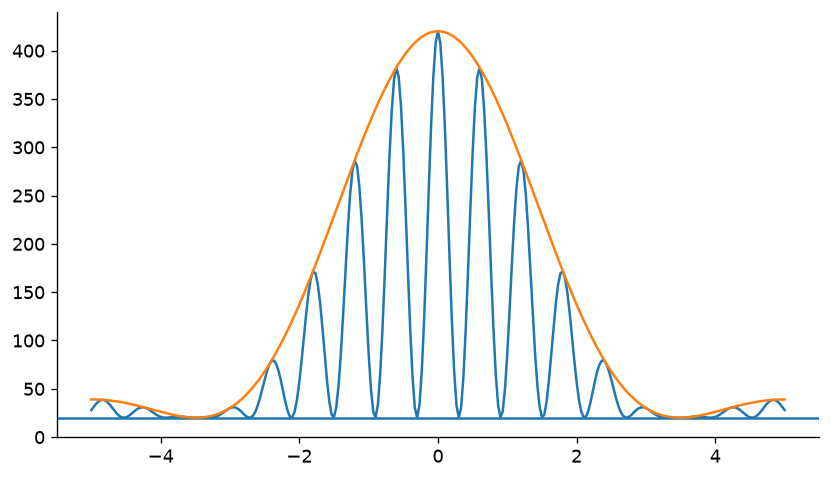

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune con accento rosso del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

# Un seed fissato rende risultati e grafici riproducibili.
rng = np.random.default_rng(4102026)
#parametri delle funzioni
b = 20
i_0 = 400
alpha = 0.9
delta = 5.2
position = np.linspace(-5.00,5.00,301)

#funzioni
def E_x (alpha, x):
    return np.sinc(alpha*x/np.pi)**2

def C_x (delta, x):
    return np.cos(delta*x)**2


def mu(alpha, x , delta, b, i_0):
    return b+i_0*(E_x(alpha = alpha, x = x))*C_x(delta = delta, x = x)

mu_var = np.array(mu(alpha, position, delta, b , i_0))

for n in range(mu_var.size) :
    assert(mu_var[n] >0)

np.testing.assert_allclose(mu_var, mu_var[::-1]) #riscrivi bene e comprensibile
assert np.isclose(mu_var[150], b + i_0)


fig, grafico = plt.subplots()
grafico.plot(position, mu_var)
grafico.axhline(b)
grafico.plot(position, b+i_0*E_x(alpha,position))
plt.show()

245.69214836634637
117.1849301387924


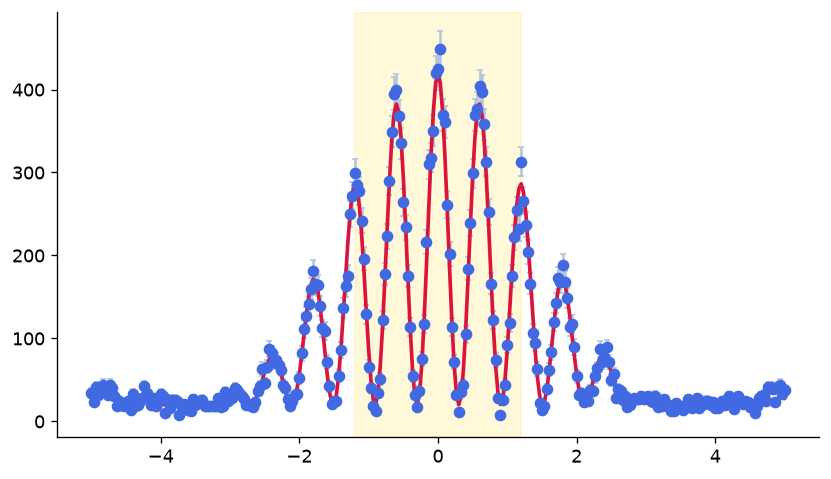

In [3]:
conteggi = rng.poisson(mu_var)
errori = np.sqrt(conteggi)
errori[errori == 0] = 1
n_centrale = np.sum(conteggi[np.abs(position)<1.2])

mu_centrale = np.sum(mu_var[np.abs(position)<1.2])


print(n_centrale-mu_centrale)
print(np.sqrt(mu_centrale))
ax, grafico = plt.subplots()
grafico.errorbar(position,conteggi, yerr = errori, fmt='o', color='royalblue', 
             ecolor='lightsteelblue', elinewidth=1.5, capsize=2, 
             label='Conteggi simulati ($n_i$)')
grafico.plot(position, mu_var, color='crimson', linewidth=2.2, 
         label='Curva attesa $\\mu(x)$')
grafico.axvspan(-1.2, 1.2, color='gold', alpha=0.15, 
            label='Regione centrale ($|x| < 1.2$ mm)')
plt.show()


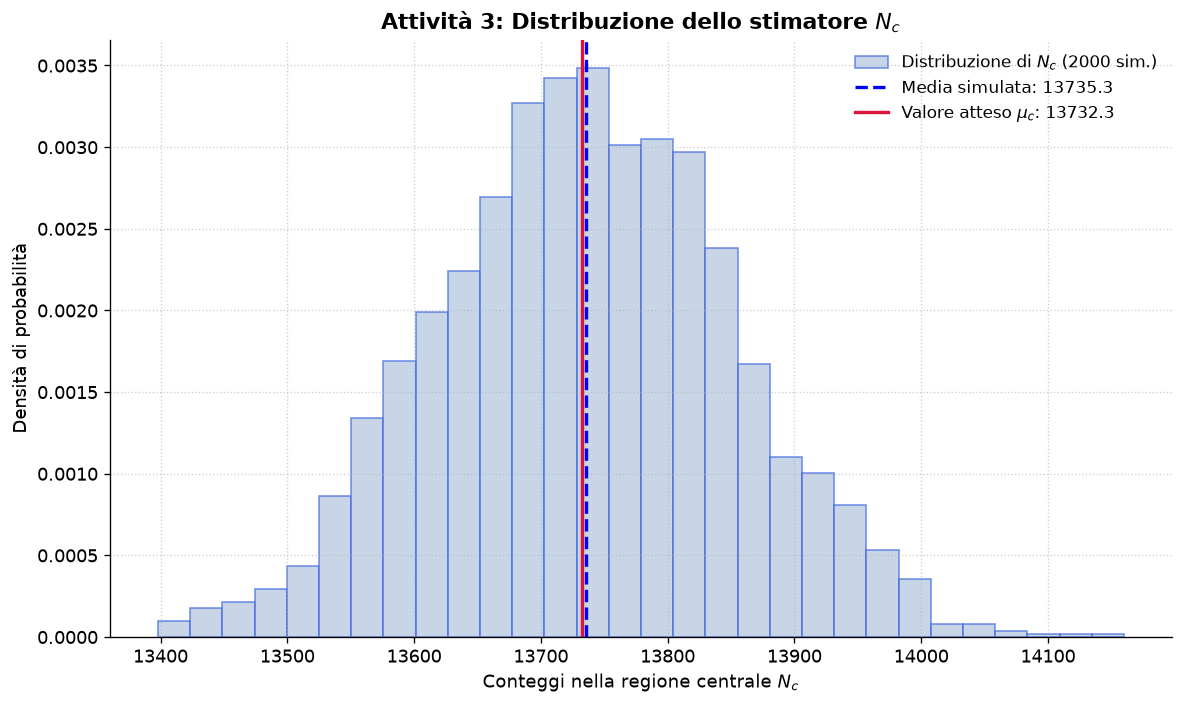

In [4]:
M = 2000
matrice = rng.poisson(mu_var, size=(M, len(position)))

N_c_sim = np.sum(matrice[:,np.abs(position)<1.2], axis = 1)
media = np.mean(N_c_sim)
dev_std = np.std(N_c_sim, ddof = 1)
err_media = dev_std/np.sqrt(M)
scarto_rel = (media-mu_centrale)/mu_centrale
dev_std_teorica = np.sqrt(mu_centrale)


plt.figure(figsize=(10, 6))
conteggi, bin_edges, _ = plt.hist(N_c_sim, bins=30, density=True, color='lightsteelblue', 
                                  edgecolor='royalblue', alpha=0.7, label='Distribuzione di $N_c$ (2000 sim.)')

# Linee verticali per evidenziare la media simulata e il valore teorico atteso
plt.axvline(media, color='blue', linestyle='--', linewidth=2, 
            label=f'Media simulata: {media:.1f}')
plt.axvline(mu_centrale, color='crimson', linestyle='-', linewidth=2, 
            label=f'Valore atteso $\\mu_c$: {mu_centrale:.1f}')

plt.title('Attività 3: Distribuzione dello stimatore $N_c$', fontsize=13, fontweight='bold')
plt.xlabel('Conteggi nella regione centrale $N_c$', fontsize=11)
plt.ylabel('Densità di probabilità', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

s      | Media <Nc(s)>  | Dev. Std. sigma | r(s)       | r(s) * sqrt(s) 
----------------------------------------------------------------------
0.25   | 3431.42        | 58.11           | 0.01694    | 0.00847        
0.50   | 6865.97        | 85.07           | 0.01239    | 0.00876        
1.00   | 13728.30       | 114.90          | 0.00837    | 0.00837        
2.00   | 27455.70       | 168.30          | 0.00613    | 0.00867        
4.00   | 54927.96       | 235.15          | 0.00428    | 0.00856        
8.00   | 109852.39      | 330.43          | 0.00301    | 0.00851        


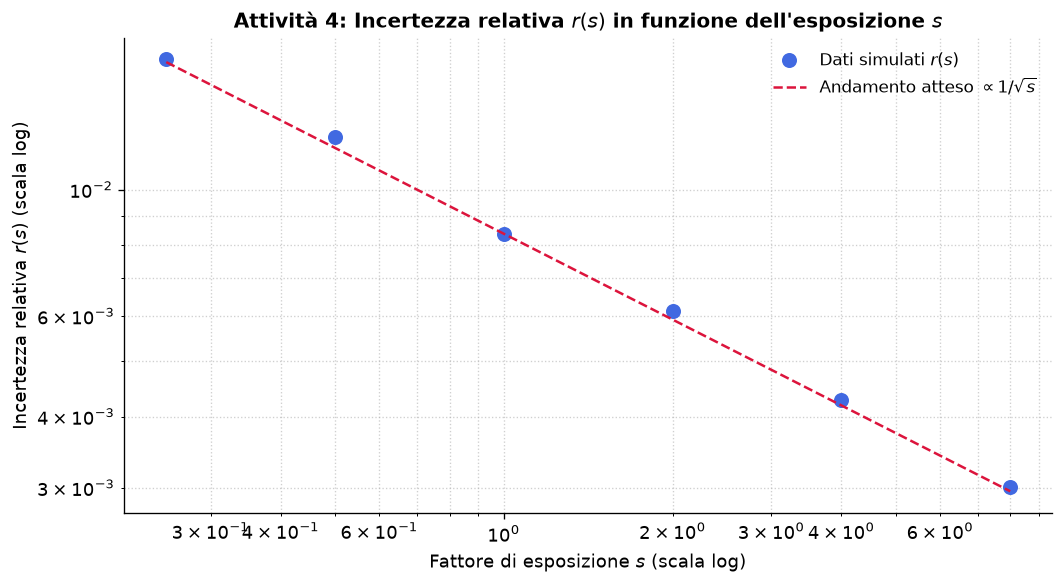

In [8]:
N = 1000
s = np.array([0.25, 0.5, 1,2, 4 ,8])
liste_medie=[]
liste_dev_std = []
liste_r_s = []

for val in s:
    mu_s = val*mu_var
    mu_c_teorico_s = val * mu_centrale
    
    # Generiamo la matrice di simulazione (1000 esperimenti x 161 canali)
    matrice_s = rng.poisson(mu_s, size=(N, len(position)))
    
    # Calcoliamo lo stimatore Nc per ogni riga (somma lungo axis=1 nella regione centrale)
    N_c_sim_s = np.sum(matrice_s[:, np.abs(position)<1.2], axis=1)
    
    # Calcolo delle grandezze statistiche empiriche
    media_empirica = np.mean(N_c_sim_s)
    dev_std_empirica = np.std(N_c_sim_s, ddof=1)
    
    # Incertezza relativa empirica r(s) = sigma_Nc / E[Nc]
    r_s = dev_std_empirica / media_empirica
    
    # Salviamo i risultati
    liste_medie.append(media_empirica)
    liste_dev_std.append(dev_std_empirica)
    liste_r_s.append(r_s)

liste_r_s = np.array(liste_r_s)

print(f"{'s':<6} | {'Media <Nc(s)>':<14} | {'Dev. Std. sigma':<15} | {'r(s)':<10} | {'r(s) * sqrt(s)':<15}")
print("-" * 70)
for i, c in enumerate(s):
    prodotto_costante = liste_r_s[i] * np.sqrt(c)
    print(f"{c:<6.2f} | {liste_medie[i]:<14.2f} | {liste_dev_std[i]:<15.2f} | {liste_r_s[i]:<10.5f} | {prodotto_costante:<15.5f}")

plt.figure(figsize=(9, 5))
plt.loglog(s, liste_r_s, 'o', color='royalblue', markersize=8, label='Dati simulati $r(s)$')

r_atteso = liste_r_s[s == 1.0][0] / np.sqrt(s)
plt.loglog(s, r_atteso, '--', color='crimson', linewidth=1.5, label=r'Andamento atteso $\propto 1/\sqrt{s}$')

plt.title('Attività 4: Incertezza relativa $r(s)$ in funzione dell\'esposizione $s$', fontsize=12, fontweight='bold')
plt.xlabel('Fattore di esposizione $s$ (scala log)', fontsize=11)
plt.ylabel('Incertezza relativa $r(s)$ (scala log)', fontsize=11)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

